We will analyze the store sales time series dataset and submit sales predictions to Kaggle competition

In [23]:
!pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 10.8 MB/s eta 0:00:00


In [2]:
import os
import kagglehub
kagglehub.login()

os.environ["KAGGLE_USERNAME"] = "tomhait"
os.environ["KAGGLE_KEY"] = "Your API key"

path = kagglehub.competition_download('store-sales-time-series-forecasting')

print("Path to competition files:", path)

100%|██████████| 21.4M/21.4M [00:00<00:00, 89.9MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/store-sales-time-series-forecasting
Kaggle credentials set.
Kaggle credentials successfully validated.


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pmdarima as pm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_log_error
import re

In [4]:
train      = pd.read_csv(path + '/train.csv',parse_dates=['date'])
test       = pd.read_csv(path + '/test.csv',parse_dates=['date'])
stores     = pd.read_csv(path + '/stores.csv')
oil        = pd.read_csv(path + '/oil.csv',parse_dates=['date'])
holidays   = pd.read_csv(path + '/holidays_events.csv', parse_dates=['date'])

In [5]:
print('First 5 rows of the train dataset:')
print(train.head())
print('First 5 rows of the stores dataset:')
print(stores.head())
print('First 5 rows of the oil dataset:')
print(oil.head())
print('First 5 rows of the holidays dataset:')
print(holidays.head())


First 5 rows of the train dataset:
   id       date  store_nbr      family  sales  onpromotion
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0
1   1 2013-01-01          1   BABY CARE    0.0            0
2   2 2013-01-01          1      BEAUTY    0.0            0
3   3 2013-01-01          1   BEVERAGES    0.0            0
4   4 2013-01-01          1       BOOKS    0.0            0
First 5 rows of the stores dataset:
   store_nbr           city                           state type  cluster
0          1          Quito                       Pichincha    D       13
1          2          Quito                       Pichincha    D       13
2          3          Quito                       Pichincha    D        8
3          4          Quito                       Pichincha    D        9
4          5  Santo Domingo  Santo Domingo de los Tsachilas    D        4
First 5 rows of the oil dataset:
        date  dcoilwtico
0 2013-01-01         NaN
1 2013-01-02       93.14
2 2013-01-03     

### Plot sales distribution over time

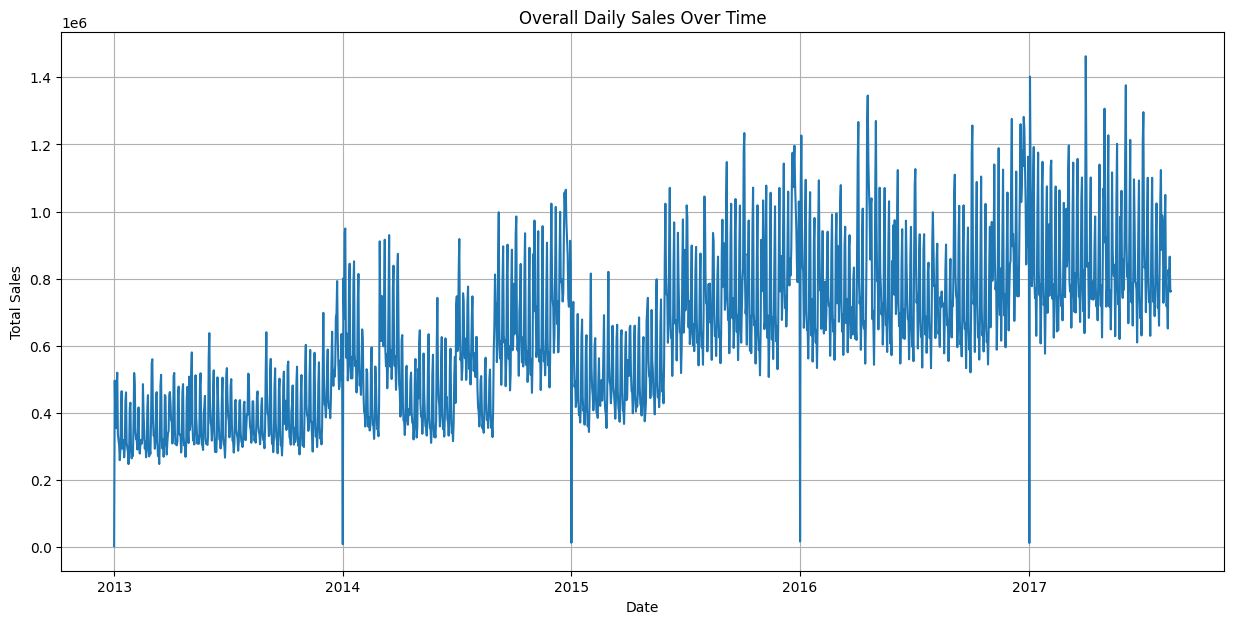

In [6]:
daily_sales = train.groupby('date')['sales'].sum().reset_index()

plt.figure(figsize=(15, 7))
sns.lineplot(x='date', y='sales', data=daily_sales)
plt.title('Overall Daily Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()

Clearly, the sales data is not stationary


### Time Series Analysis: Stationarity, Seasonality, Trend, and Autocorrelation

#### 1. Stationarity Test

We'll use the Augmented Dickey-Fuller (ADF) test to check for stationarity. A stationary time series has properties that do not depend on the time at which the series is observed. Most time series models assume stationarity.

In [7]:
result = adfuller(daily_sales['sales'])

print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:')
for key, value in result[4].items():
    print(f'\t{key}: {value}')

if result[1] <= 0.05:
    print("\nThe time series is likely stationary (reject H0).")
else:
    print("\nThe time series is likely non-stationary (fail to reject H0).")

ADF Statistic: -2.6161957486048566
p-value: 0.08969592175787472
Critical Values:
	1%: -3.4342930672797065
	5%: -2.8632816397229064
	10%: -2.567697207194407

The time series is likely non-stationary (fail to reject H0).


#### 2. Seasonality and Trend Decomposition


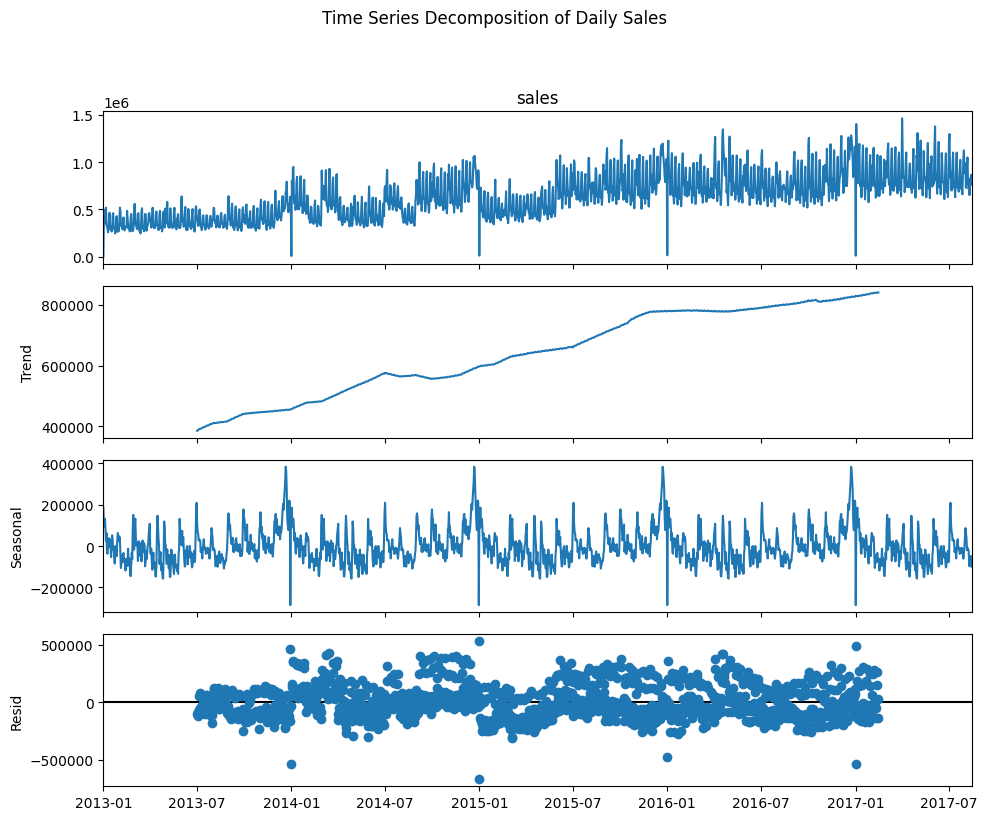

In [9]:
daily_sales_indexed = daily_sales.set_index('date')
decomposition = seasonal_decompose(daily_sales_indexed['sales'], model='additive', period=365)

fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.suptitle('Time Series Decomposition of Daily Sales', y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

We can clearly see the trend line and seasonalities decompsed from the sales data

### Making the Time Series Stationary (Differencing)

#### First-Order Differencing

We'll apply a first-order difference to our `daily_sales` data.

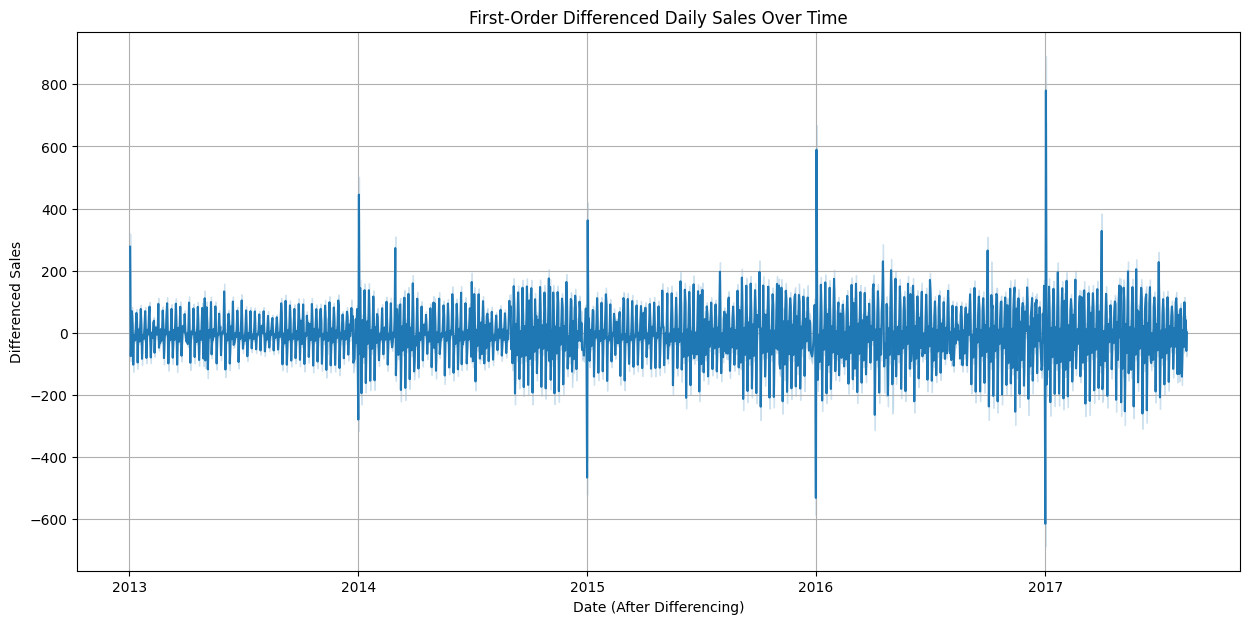

,date,store_nbr,family,sales,onpromotion,sales_diff
0,2013-01-01,1,AUTOMOTIVE,0.0,0,NaN
1,2013-01-01,1,BABY CARE,0.0,0,NaN
2,2013-01-01,1,BEAUTY,0.0,0,NaN
3,2013-01-01,1,BEVERAGES,0.0,0,NaN
4,2013-01-01,1,BOOKS,0.0,0,NaN


In [11]:
daily_sales = train.groupby(['date','store_nbr','family']).agg({'sales': 'sum', 'onpromotion': 'sum'}).reset_index()

daily_sales['sales_diff'] = daily_sales.groupby(['store_nbr','family'])['sales'].diff()

plt.figure(figsize=(15, 7))
sns.lineplot(x='date', y='sales_diff', data=daily_sales.iloc[1:])
plt.title('First-Order Differenced Daily Sales Over Time')
plt.xlabel('Date (After Differencing)')
plt.ylabel('Differenced Sales')
plt.grid(True)
plt.show()

display(daily_sales.head())

Now the sales data seems stationary


#### Re-test for Stationarity (ADF Test) on Differenced Data


In [12]:
result_diff = adfuller(daily_sales['sales_diff'].dropna(), autolag=None, maxlag=10)

print('ADF Statistic (Differenced):', result_diff[0])
print('p-value (Differenced):', result_diff[1])
print('Critical Values (Differenced):')
for key, value in result_diff[4].items():
    print(f'\t{key}: {value}')

if result_diff[1] <= 0.05:
    print("\nThe differenced time series is likely stationary (reject H0).")
else:
    print("\nThe differenced time series is likely non-stationary (fail to reject H0).")

ADF Statistic (Differenced): -348.68264030630843
p-value (Differenced): 0.0
Critical Values (Differenced):
	1%: -3.430352180426294
	5%: -2.8615409637245275
	10%: -2.5667705129550535

The differenced time series is likely stationary (reject H0).


## ARIMA for Sales Prediction

To apply ARIMA, we will use the `pmdarima` library, which offers `auto_arima` for automatically selecting the best ARIMA model parameters. We will demonstrate ARIMA on a single time series (e.g., `store_nbr` 1 and `family` 'AUTOMOTIVE').

In [26]:
example_series_df = daily_sales[(daily_sales['store_nbr'] == 1) & (daily_sales['family'] == 'AUTOMOTIVE')].set_index('date').sort_index()
example_series = example_series_df['sales']

print("\nFitting auto_arima model...")
model = pm.auto_arima(example_series, seasonal=True, m=7,
                      d=None,
                      D=None,
                      max_p=5, max_q=5, max_P=2, max_Q=2,
                      trace=True, error_action='ignore', suppress_warnings=True,
                      stepwise=True)

print("\nAuto ARIMA model fitting complete.")
print(model.summary())


Fitting auto_arima model...
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=inf, Time=8.83 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=9184.997, Time=0.06 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=8751.583, Time=0.67 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=8048.950, Time=2.28 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=9182.998, Time=0.10 sec
 ARIMA(0,1,1)(0,0,0)[7] intercept   : AIC=8054.102, Time=1.52 sec
 ARIMA(0,1,1)(1,0,1)[7] intercept   : AIC=inf, Time=7.99 sec
 ARIMA(0,1,1)(0,0,2)[7] intercept   : AIC=8030.554, Time=4.60 sec
 ARIMA(0,1,1)(1,0,2)[7] intercept   : AIC=inf, Time=16.30 sec
 ARIMA(0,1,0)(0,0,2)[7] intercept   : AIC=9156.529, Time=0.92 sec
 ARIMA(1,1,1)(0,0,2)[7] intercept   : AIC=8032.412, Time=5.49 sec
 ARIMA(0,1,2)(0,0,2)[7] intercept   : AIC=8032.398, Time=7.21 sec
 ARIMA(1,1,0)(0,0,2)[7] intercept   : AIC=8731.272, Time=1.19 sec
 ARIMA(1,1,2)(0,0,2)[7] intercept   : AIC=8030.094, Time=12.05 sec
 ARIMA(1,1,2)(0,0

### Plotting ARIMA Model Predictions

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


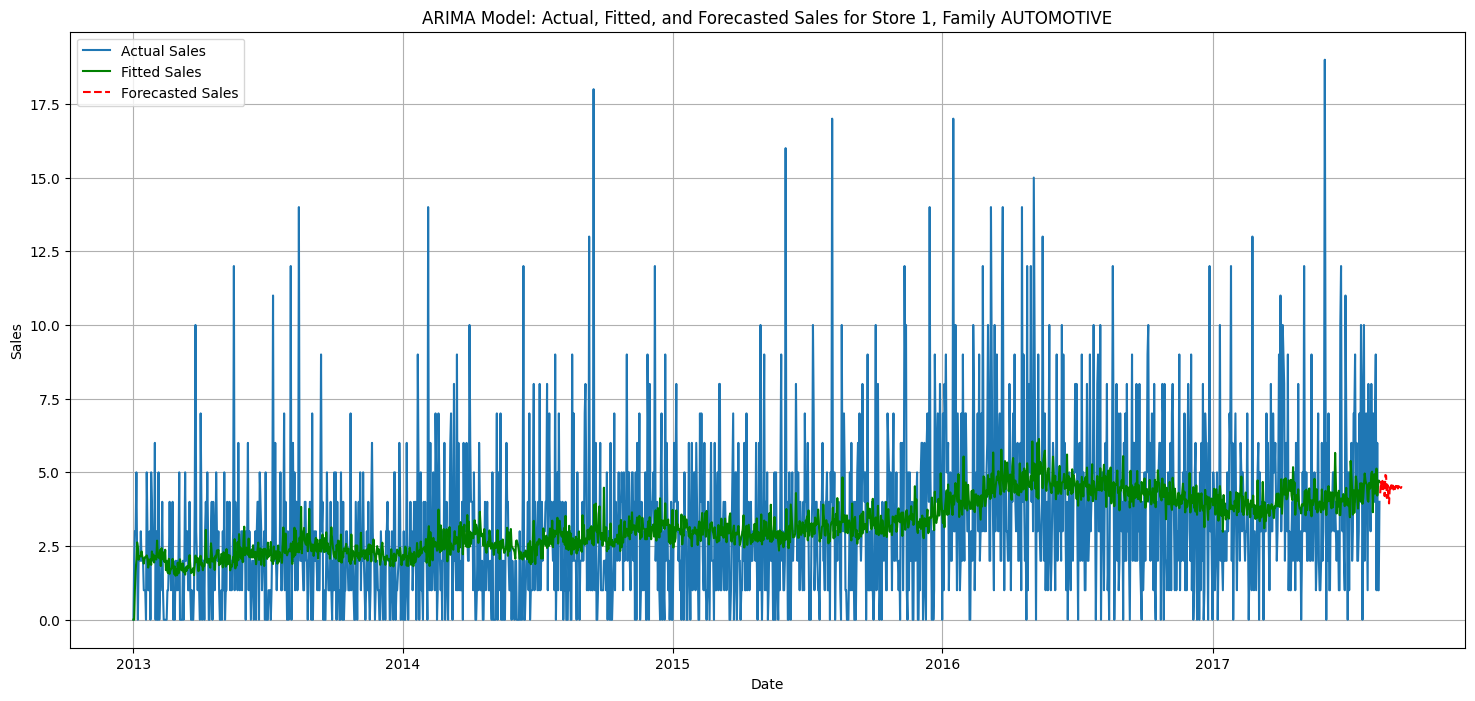

In [31]:
fitted_values = model.predict_in_sample(exog=None)

n_periods = 30
forecast = model.predict(n_periods=n_periods)

last_date = example_series.index.max()
forecast_index = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_periods, freq='D')
forecast_series = pd.Series(forecast.values, index=forecast_index)

plt.figure(figsize=(18, 8))
plt.plot(example_series.index, example_series, label='Actual Sales')
plt.plot(example_series.index, fitted_values, color='green', label='Fitted Sales')
plt.plot(forecast_series.index, forecast_series, color='red', linestyle='--', label='Forecasted Sales')

plt.title('ARIMA Model: Actual, Fitted, and Forecasted Sales for Store 1, Family AUTOMOTIVE')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

This is a toy example of using ARIMA to forecast sales during 30 days in the future. We will not use it for prediction as ARIMA is univariate, which means it does not incorporate external or independent variables to make predictions.

### Merging `daily_sales` with external datasets

In [22]:
processed_holidays = holidays.copy()

processed_holidays['is_actual_holiday'] = 0

processed_holidays.loc[
    ((processed_holidays['type'] == 'Holiday') & (processed_holidays['transferred'] == False)) |
    (processed_holidays['type'] == 'Transfer'),
    'is_actual_holiday'
] = 1

processed_holidays.loc[
    (processed_holidays['type'] == 'Holiday') & (processed_holidays['transferred'] == True),
    'is_actual_holiday'
] = 0

holidays_aggregated = processed_holidays.groupby('date').agg(
    is_holiday=('is_actual_holiday', 'max'),
    description=('description', lambda x: ', '.join(x.dropna().astype(str).unique())),
    type_holiday=('type', lambda x: ', '.join(x.dropna().astype(str).unique()))
).reset_index()

holidays_aggregated.head()

,date,is_holiday,description,type_holiday
0,2012-03-02,1,Fundacion de Manta,Holiday
1,2012-04-01,1,Provincializacion de Cotopaxi,Holiday
2,2012-04-12,1,Fundacion de Cuenca,Holiday
3,2012-04-14,1,Cantonizacion de Libertad,Holiday
4,2012-04-21,1,Cantonizacion de Riobamba,Holiday


In [14]:
categorical_features = ['family', 'city', 'state', 'type', 'cluster']
numerical_features = [
    'onpromotion', 'dcoilwtico',
    'year', 'month', 'day', 'dayofweek', 'dayofyear', 'weekofyear',
    'quarter', 'is_weekend', 'is_month_start', 'is_month_end', 'is_holiday'
]

def merge_datasets(df):
    df = pd.merge(df, oil, on='date', how='left')
    df['dcoilwtico'] = df['dcoilwtico'].ffill()
    df = pd.merge(df, holidays_aggregated, on='date', how='left')
    df['is_holiday'] = df['is_holiday'].fillna(0)
    df = df.drop(columns=['type_holiday','description'])
    df = pd.merge(df, stores, on='store_nbr', how='left')
    df['year'] = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['dayofweek'] = df['date'].dt.dayofweek
    df['dayofyear'] = df['date'].dt.dayofyear
    df['weekofyear'] = df['date'].dt.isocalendar().week.astype(int)
    df['quarter'] = df['date'].dt.quarter
    df['is_weekend'] = (df['date'].dt.dayofweek >= 5).astype(int)
    df['is_month_start'] = df['date'].dt.is_month_start.astype(int)
    df['is_month_end'] = df['date'].dt.is_month_end.astype(int)
    df['dcoilwtico'] = df['dcoilwtico'].fillna(df['dcoilwtico'].mean())
    df = pd.get_dummies(df, columns=categorical_features, dummy_na=False)
    return df

A function to fix column names for training

In [20]:
def sanitize_col_names(df):
    new_cols = []
    for col in df.columns:
        col = col.replace('+', '_plus_').replace('-', '_minus_')

        col = re.sub(r'[^A-Za-z0-9_]+', '_', col)
        col = re.sub(r'_+', '_', col).strip('_')
        new_cols.append(col)

    final_cols = []
    col_counts = {}
    for col in new_cols:
        if col in col_counts:
            col_counts[col] += 1
            final_cols.append(f"{col}_{col_counts[col]}")
        else:
            col_counts[col] = 0
            final_cols.append(col)

    df.columns = final_cols
    return df

In [15]:
df = train.copy()
df = merge_datasets(df)
df.head()

,id,date,store_nbr,sales,onpromotion,dcoilwtico,is_holiday,year,month,day,...,cluster_8,cluster_9,cluster_10,cluster_11,cluster_12,cluster_13,cluster_14,cluster_15,cluster_16,cluster_17
0,0,2013-01-01,1,0.0,0,67.909917,1.0,2013,1,1,...,False,False,False,False,False,True,False,False,False,False
1,1,2013-01-01,1,0.0,0,67.909917,1.0,2013,1,1,...,False,False,False,False,False,True,False,False,False,False
2,2,2013-01-01,1,0.0,0,67.909917,1.0,2013,1,1,...,False,False,False,False,False,True,False,False,False,False
3,3,2013-01-01,1,0.0,0,67.909917,1.0,2013,1,1,...,False,False,False,False,False,True,False,False,False,False
4,4,2013-01-01,1,0.0,0,67.909917,1.0,2013,1,1,...,False,False,False,False,False,True,False,False,False,False


### Drop Unnecessary Columns

In [16]:
train_df = df.drop(columns=['date','id'])

print("\nDataFrame after preprocessing:")
print(train_df.head())


DataFrame after preprocessing:
   store_nbr  sales  onpromotion  dcoilwtico  is_holiday  year  month  day  \
0          1    0.0            0   67.909917         1.0  2013      1    1   
1          1    0.0            0   67.909917         1.0  2013      1    1   
2          1    0.0            0   67.909917         1.0  2013      1    1   
3          1    0.0            0   67.909917         1.0  2013      1    1   
4          1    0.0            0   67.909917         1.0  2013      1    1   

   dayofweek  dayofyear  ...  cluster_8  cluster_9  cluster_10  cluster_11  \
0          1          1  ...      False      False       False       False   
1          1          1  ...      False      False       False       False   
2          1          1  ...      False      False       False       False   
3          1          1  ...      False      False       False       False   
4          1          1  ...      False      False       False       False   

   cluster_12  cluster_13  clu

In [17]:
X = train_df.drop('sales', axis=1)
y = train_df['sales']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (3000888, 107)
Target (y) shape: (3000888,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2400710, 107)
X_test shape: (600178, 107)
y_train shape: (2400710,)
y_test shape: (600178,)


We will run the random forest locally

In [ ]:
rf = RandomForestRegressor(random_state=42, n_estimators=100, n_jobs=8)
X_train = sanitize_col_names(X_train.copy())
X_test = sanitize_col_names(X_test.copy())

print("Training Random Forest model...")
rf.fit(X_train, y_train)
print("Random Forest model trained successfully.")

In [ ]:
y_pred = rf.predict(X_test)

rmsle_score = mean_squared_log_error(y_test, y_pred)

print(f"Root Mean Squared Logarithmic Error (RMSLE): {rmsle_score:.3f}")

Root Mean Squared Logarithmic Error (RMSLE): 0.476

### Train on all train dataset

In [ ]:
print("Training Random Forest model...")
rf.fit(X, y)
print("Random Forest model trained successfully.")

### Report results on test set

In [21]:
df = merge_datasets(test)
test_df = df.drop(columns=['date','id'])

print("\nDataFrame after preprocessing:")
print(test_df.head())


DataFrame after preprocessing:
   store_nbr  onpromotion  dcoilwtico  is_holiday  year  month  day  \
0          1            0        46.8         0.0  2017      8   16   
1          1            0        46.8         0.0  2017      8   16   
2          1            2        46.8         0.0  2017      8   16   
3          1           20        46.8         0.0  2017      8   16   
4          1            0        46.8         0.0  2017      8   16   

   dayofweek  dayofyear  weekofyear  ...  cluster_8  cluster_9  cluster_10  \
0          2        228          33  ...      False      False       False   
1          2        228          33  ...      False      False       False   
2          2        228          33  ...      False      False       False   
3          2        228          33  ...      False      False       False   
4          2        228          33  ...      False      False       False   

   cluster_11  cluster_12  cluster_13  cluster_14  cluster_15  cluster_1

In [ ]:
y_test_pred = rf.predict(test_df)

In [ ]:
submission = pd.DataFrame({'id': test['id'], 'sales': y_test_pred})

submission.to_csv('submission.csv', index=False)

print("Submission file 'submission.csv' created successfully.")
print(submission.head())

### Kaggle public score 0.5218
